# Problem 15 - Traveling Salesperson Problem (TSP)

## Part C - Implementation & Empirical Benchmarking Lab

In this notebook we compare **all five stages** on random maps, as required in Part C of the problem sheet:

- **Experiment 1:** exact optimality (V1 = V3) and approximation ratios of V2, V4, V5a, V5b at n = 11 and n = 16.
- **Experiment 2:** visual uncrossing of a 150-city route and the convergence of Simulated Annealing.
- **Question 5:** the largest n each stage solves in under 1 second, and the final comparison table.

The code of every stage is copied from our stage notebooks, so this notebook can run on its own:
`tsp_part1.ipynb` (Stages 1-2), `held-karp-algorithm.ipynb` (Stage 3), `tsp_stage4_mst.ipynb` (Stage 4), `tsp_stage5_2opt_sa.ipynb` (Stage 5).

## Shared Helpers and the 4-City Matrix

In [1]:
import math
import random

D = [
    [0, 10, 15, 20],
    [10, 0, 35, 25],
    [15, 35, 0, 30],
    [20, 25, 30, 0]
]

print("Number of cities:", len(D))


def route_cost(route, D):
    total = 0

    for i in range(len(route) - 1):
        from_city = route[i]
        to_city = route[i + 1]

        total += D[from_city][to_city]

    return total

Number of cities: 4


## Stage 5 - 2-Opt and Simulated Annealing (from the Stage 5 notebook)

In [2]:
def two_opt_delta(route, i, j, D):
    u1, v1 = route[i], route[i + 1]      # first edge we remove
    u2, v2 = route[j], route[j + 1]      # second edge we remove

    added = D[u1][u2] + D[v1][v2]        # two new edges
    removed = D[u1][v1] + D[u2][v2]      # two old edges

    return added - removed


def two_opt_move(route, i, j):
    # Reverse the part route[i+1 .. j]
    return route[:i + 1] + route[i + 1:j + 1][::-1] + route[j + 1:]


def two_opt(route, D, show_steps=False):
    route = route[:]
    n = len(route) - 1                       # number of cities (start city is repeated at the end)
    improved = True

    while improved:
        improved = False
        for i in range(n - 1):
            for j in range(i + 2, n):
                if i == 0 and j == n - 1:
                    continue                 # these two edges touch city route[0]
                delta = two_opt_delta(route, i, j, D)
                if delta < -1e-9:
                    route = two_opt_move(route, i, j)
                    improved = True
                    if show_steps:
                        print(f"i={i}, j={j}, delta={delta:.1f} -> {route}, distance {route_cost(route, D):.1f}")

    return route, route_cost(route, D)



def simulated_annealing(route, D, T_start=None, gamma=0.995, T_end=0.001, moves_per_T=None,
                        seed=0, history=False):
    rng = random.Random(seed)
    route = route[:]
    n = len(route) - 1
    current = route_cost(route, D)
    best_route, best = route[:], current

    if n < 4:
        return (best_route, best, []) if history else (best_route, best)
    if T_start is None:                       # 10 % of the average distance between two cities
        T_start = 0.1 * sum(map(sum, D)) / (n * (n - 1))
    if moves_per_T is None:
        moves_per_T = 10 * n

    T, step, log = T_start, 0, []
    while T > T_end:
        for _ in range(moves_per_T):
            i, j = sorted(rng.sample(range(n), 2))         # random pair of edges
            if j - i < 2 or (i == 0 and j == n - 1):
                continue
            delta = two_opt_delta(route, i, j, D)
            if delta < 0 or rng.random() < math.exp(-delta / T):
                route = two_opt_move(route, i, j)
                current += delta
                if current < best:                        # remember the best route ever seen
                    best_route, best = route[:], current
            step += 1
            if history and step % 200 == 0:
                log.append((step, current, best, T))
        T *= gamma                                        # cool down

    best_route, best = two_opt(best_route, D)             # final polish with normal 2-Opt
    return (best_route, best, log) if history else (best_route, best)

## Stages 1-4 (from our other notebooks) and the Stage 5 Versions

- **V5a = Greedy + 2-Opt:** start from the Nearest Neighbor route, then run 2-Opt.
- **V5b = 2-Opt + Simulated Annealing:** start from the Nearest Neighbor route, then run Simulated Annealing with 2-Opt moves.

In [3]:
from itertools import permutations
import sys

sys.setrecursionlimit(10000)   # dfs_preorder (Stage 4) is recursive; deep trees appear for thousands of cities


# ---------- From Stage 4 notebook ----------
def random_cities(n, seed):
    rng = random.Random(seed)
    return [(rng.uniform(0, 100), rng.uniform(0, 100)) for _ in range(n)]


def distance_matrix(points):
    n = len(points)
    return [[math.dist(points[i], points[j]) for j in range(n)] for i in range(n)]


# ---------- Stage 1 - Brute Force (from the Stage 1-2 notebook) ----------
def brute_force(D, show_routes=False):
    n = len(D)
    best_distance = float("inf")
    best_route = []

    # Generate all possible orders of cities except city 0
    for order in permutations(range(1, n)):

        # Skip reversed routes because distances are symmetric
        if len(order) > 1 and order[0] > order[-1]:
            continue

        # Start and finish at city 0
        route = [0] + list(order) + [0]

        # Calculate total distance
        distance = route_cost(route, D)

        if show_routes:
            print("Route:", route, "Distance:", distance)

        # Save the shortest route
        if distance < best_distance:
            best_distance = distance
            best_route = route

    return best_route, best_distance


# ---------- Stage 2 - Nearest Neighbor (from the Stage 1-2 notebook) ----------
def nearest_neighbor(D, start=0):
    n = len(D)
    route = [start]
    unvisited = list(range(n))
    unvisited.remove(start)
    current = start

    # Keep going until all cities are visited
    while unvisited:

        # Find the closest unvisited city
        next_city = min(unvisited, key=lambda city: D[current][city])

        route.append(next_city)
        unvisited.remove(next_city)
        current = next_city

    # Return to starting city
    route.append(start)

    # Calculate total distance
    total_distance = route_cost(route, D)

    return route, total_distance


# ---------- Stage 3 - Held-Karp (from the Stage 3 notebook) ----------
# Note: returns (minimum_distance, route)
def held_karp(distance):
    n = len(distance)
    all_visited = (1 << n) - 1

    # variables to store the calculation and the best next path
    memo = {}
    best_path = {}

    # tsp - travel salesperson problem
    def tsp(current_city, visited_city): 

        # Base case: all cities have been visited
        if visited_city == all_visited:
            return distance[current_city][0]

        # Check memoization
        if (current_city, visited_city) in memo:
            return memo[(current_city, visited_city)]

        minimum_cost = float("inf")

        # Try every unvisited city
        for next_city in range(n):

            if not (visited_city & (1 << next_city)):

                new_visited = visited_city | (1 << next_city)

                cost = (
                    distance[current_city][next_city]
                    + tsp(next_city, new_visited)
                )

                if cost < minimum_cost:
                    minimum_cost = cost
                    best_path[(current_city, visited_city)] = next_city

        # Save the minimum cost
        memo[(current_city, visited_city)] = minimum_cost

        return minimum_cost

    # Start at C0
    minimum_distance = tsp(0, 1)

    # Reconstruct the optimal route
    route = [0]
    current_city = 0
    visited_city = 1

    while visited_city != all_visited:

        next_city = best_path[(current_city, visited_city)]

        route.append(next_city)

        visited_city |= 1 << next_city
        current_city = next_city

    # Return to starting city
    route.append(0)

    return minimum_distance, route


# ---------- Stage 4 - MST Approximation (from the Stage 4 notebook) ----------
def prim_mst(D, start=0, show_steps=False):
    n = len(D)
    in_tree = [False] * n
    key = [float("inf")] * n     # cheapest edge from the tree to each city
    parent = [None] * n          # which tree city that edge comes from
    key[start] = 0

    mst_edges = []
    total = 0

    for step in range(n):
        # Pick the city outside the tree with the cheapest connecting edge
        u = None
        for v in range(n):
            if not in_tree[v] and (u is None or key[v] < key[u]):
                u = v

        in_tree[u] = True

        if parent[u] is not None:
            mst_edges.append((parent[u], u))
            total += D[parent[u]][u]
            if show_steps:
                print("Add edge", parent[u], "-", u, "weight:", D[parent[u]][u])

        # Update the cheapest edges for cities that are not in the tree yet
        for v in range(n):
            if not in_tree[v] and D[u][v] < key[v]:
                key[v] = D[u][v]
                parent[v] = u

    return mst_edges, total


def build_children(mst_edges, n):
    # For each city, the list of its children in the tree
    children = [[] for _ in range(n)]
    for parent, child in mst_edges:
        children[parent].append(child)
    return children


def dfs_preorder(city, children, order):
    order.append(city)               # write the city down on the first visit
    for child in children[city]:
        dfs_preorder(child, children, order)
    return order


def mst_approximation(D, start=0):
    n = len(D)

    # Step 1: build the MST
    mst_edges, mst_cost = prim_mst(D, start)

    # Step 2: DFS preorder of the tree
    children = build_children(mst_edges, n)
    order = dfs_preorder(start, children, [])

    # Step 3: return to the starting city
    route = order + [start]
    total_distance = route_cost(route, D)

    return route, total_distance


# ---------- Stage 5 (this notebook) ----------
def greedy_two_opt(D):
    start_route, _ = nearest_neighbor(D)
    return two_opt(start_route, D)


def two_opt_annealing(D, seed=0):
    start_route, _ = nearest_neighbor(D)
    return simulated_annealing(start_route, D, seed=seed)


print("4-city check:")
print("  Brute Force :", brute_force(D))
print("  Held-Karp   :", held_karp(D))
print("  Greedy+2-Opt:", greedy_two_opt(D))
print("  2-Opt + SA  :", two_opt_annealing(D))

4-city check:
  Brute Force : ([0, 1, 3, 2, 0], 80)
  Held-Karp   : (80, [0, 1, 3, 2, 0])
  Greedy+2-Opt: ([0, 1, 3, 2, 0], 80)
  2-Opt + SA  : ([0, 1, 3, 2, 0], 80)


## Experiment 1 - Exact Optimality and Approximation Ratios

As required in Part C:

- 20 random maps with **n = 11** cities: Brute Force (V1) and Held-Karp (V3) must return **exactly the same OPT**.
- 20 random maps with **n = 16** cities: V2-V5 compared with OPT from Held-Karp (Brute Force would take too long).

**Approximation ratio** = route / OPT (1.00 means optimal).

In [4]:
import time

ALGORITHMS = {
    "V2 Nearest Neighbor": nearest_neighbor,
    "V4 MST Approx.": mst_approximation,
    "V5a Greedy + 2-Opt": greedy_two_opt,
    "V5b 2-Opt + SA": two_opt_annealing,
}


def experiment_1(n, use_brute_force, maps=20):
    ratios = {name: [] for name in ALGORITHMS}
    times = {name: [] for name in ["V1 Brute Force", "V3 Held-Karp"] + list(ALGORITHMS)}

    for seed in range(maps):
        D_test = distance_matrix(random_cities(n, seed))

        t = time.perf_counter()
        opt, _ = held_karp(D_test)
        times["V3 Held-Karp"].append(time.perf_counter() - t)

        if use_brute_force:
            t = time.perf_counter()
            _, bf = brute_force(D_test)
            times["V1 Brute Force"].append(time.perf_counter() - t)
            assert abs(bf - opt) < 1e-9, "Brute Force and Held-Karp disagree!"

        for name, algorithm in ALGORITHMS.items():
            t = time.perf_counter()
            route, cost = algorithm(D_test)
            times[name].append(time.perf_counter() - t)
            assert sorted(route[:-1]) == list(range(n))   # every city exactly once
            ratios[name].append(cost / opt)

    print(f"n = {n}, {maps} random maps" + ("  (V1 == V3 on every map: OK)" if use_brute_force else ""))
    print(f"{'Algorithm':22} {'avg ratio':>10} {'worst':>8} {'optimal':>9} {'avg time [s]':>13}")
    for name in times:
        if not times[name]:
            continue
        avg_t = sum(times[name]) / len(times[name])
        if name in ratios:
            r = ratios[name]
            n_opt = sum(x < 1 + 1e-9 for x in r)
            print(f"{name:22} {sum(r) / len(r):10.3f} {max(r):8.3f} {n_opt:>6}/{maps} {avg_t:13.5f}")
        else:
            print(f"{name:22} {1:10.3f} {1:8.3f} {maps:>6}/{maps} {avg_t:13.5f}")
    return ratios


ratios_11 = experiment_1(11, use_brute_force=True)
print()
ratios_16 = experiment_1(16, use_brute_force=False)

n = 11, 20 random maps  (V1 == V3 on every map: OK)
Algorithm               avg ratio    worst   optimal  avg time [s]
V1 Brute Force              1.000    1.000     20/20       1.74435
V3 Held-Karp                1.000    1.000     20/20       0.01301
V2 Nearest Neighbor         1.125    1.380      1/20       0.00002
V4 MST Approx.              1.182    1.297      0/20       0.00003
V5a Greedy + 2-Opt          1.009    1.056     13/20       0.00004
V5b 2-Opt + SA              1.000    1.000     20/20       0.29800



n = 16, 20 random maps
Algorithm               avg ratio    worst   optimal  avg time [s]
V3 Held-Karp                1.000    1.000     20/20       0.87529
V2 Nearest Neighbor         1.123    1.421      1/20       0.00003
V4 MST Approx.              1.215    1.368      1/20       0.00004
V5a Greedy + 2-Opt          1.012    1.065     12/20       0.00007
V5b 2-Opt + SA              1.000    1.000     20/20       0.44399


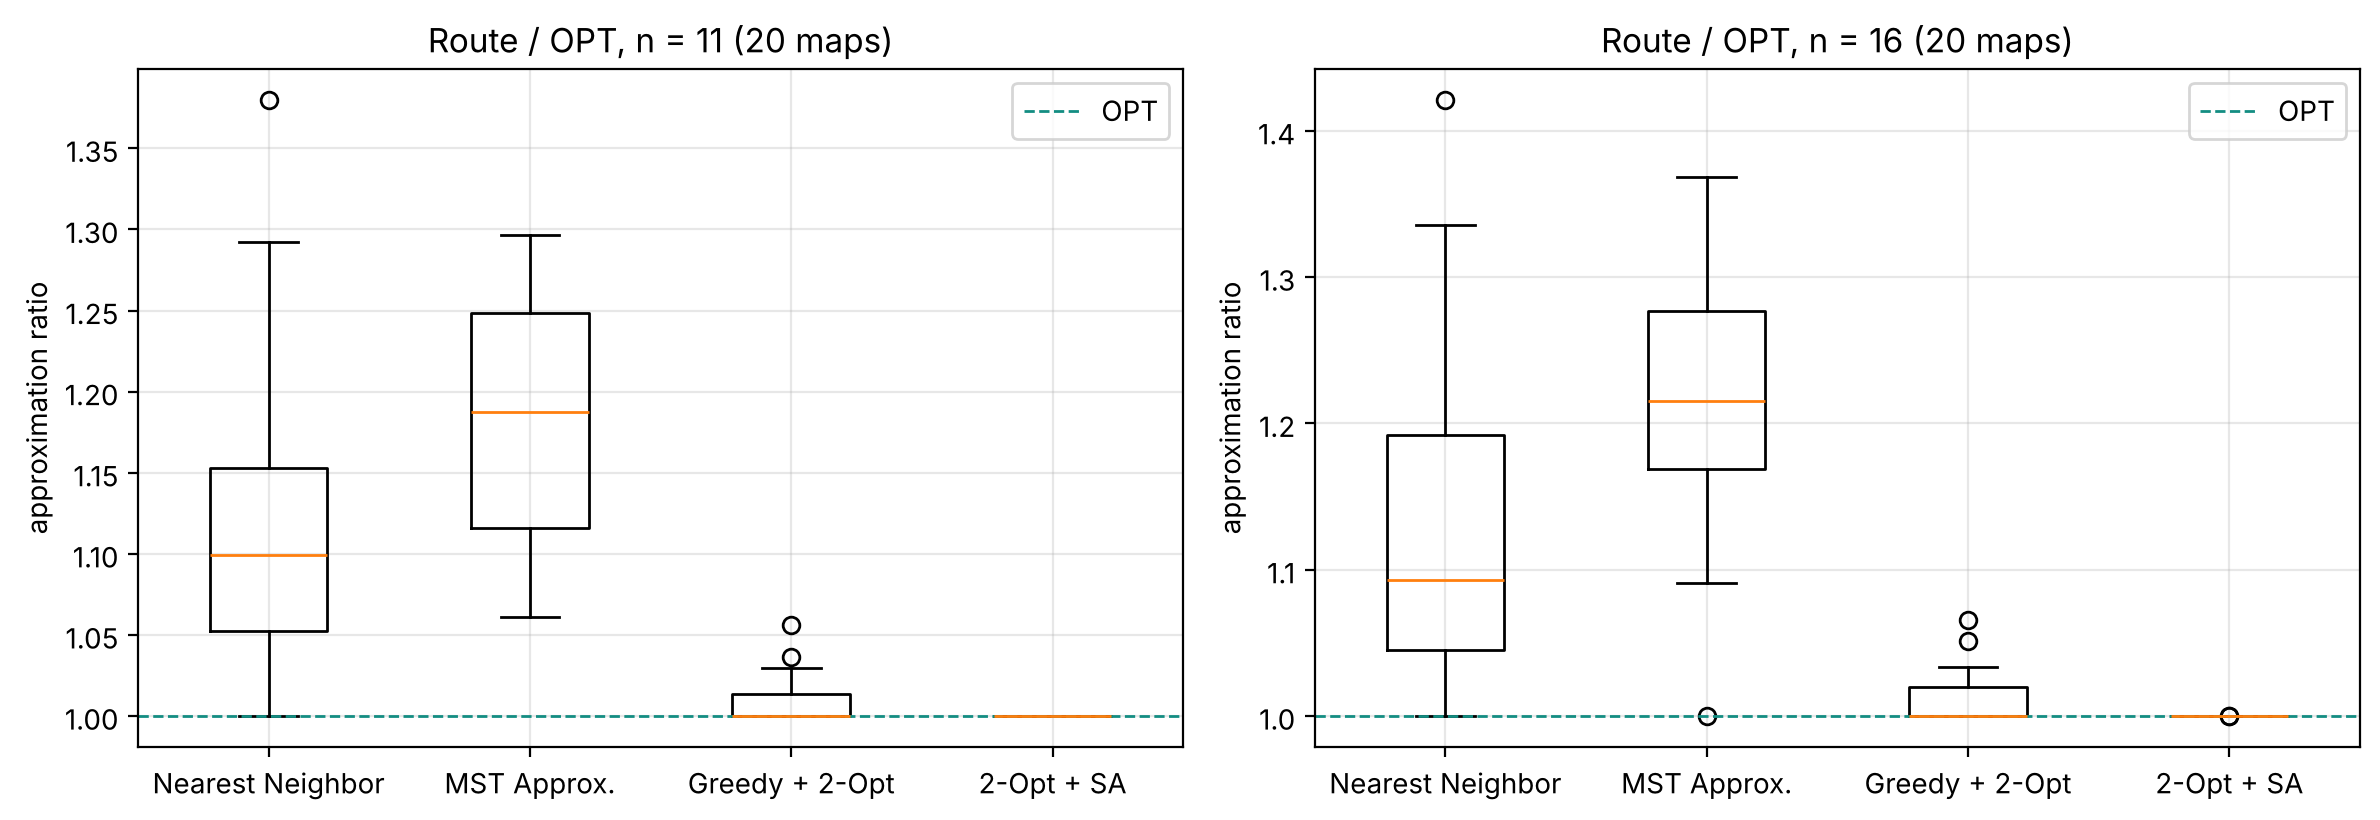

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (n, r) in zip(axes, [(11, ratios_11), (16, ratios_16)]):
    names = list(r)
    ax.boxplot([r[k] for k in names], tick_labels=[k.split(" ", 1)[1] for k in names])
    ax.axhline(1.0, color="#138D82", ls="--", lw=1, label="OPT")
    ax.set_title(f"Route / OPT, n = {n} (20 maps)")
    ax.set_ylabel("approximation ratio")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig("stage5_exp1_ratios.png", dpi=160, bbox_inches="tight")
plt.show()

## Experiment 2 - Visual Uncrossing of a 150-City Route

As required in Part C we draw, for the same 150 random cities:

(a) a random route, (b) Nearest Neighbor (V2), (c) MST approximation (V4), (d) 2-Opt + Simulated Annealing (V5),

and the **convergence curve** of Simulated Annealing.

In [6]:
points = random_cities(150, seed=7)
D_big = distance_matrix(points)

rng = random.Random(1)
order = list(range(150))
rng.shuffle(order)
random_route = order + [order[0]]

nn_route, nn_cost = nearest_neighbor(D_big)
mst_route, mst_cost = mst_approximation(D_big)
opt2_route, opt2_cost = two_opt(nn_route, D_big)

t = time.perf_counter()
sa_route, sa_cost, sa_log = simulated_annealing(nn_route, D_big, seed=1, history=True)
print(f"Simulated Annealing time: {time.perf_counter() - t:.1f} s\n")

for name, cost in [("(a) Random route", route_cost(random_route, D_big)),
                   ("(b) Nearest Neighbor", nn_cost),
                   ("(c) MST approximation", mst_cost),
                   ("    Greedy + 2-Opt", opt2_cost),
                   ("(d) 2-Opt + SA", sa_cost)]:
    print(f"{name:24} {cost:8.1f}")

Simulated Annealing time: 5.1 s

(a) Random route           8399.6
(b) Nearest Neighbor       1239.5
(c) MST approximation      1279.8
    Greedy + 2-Opt         1034.7
(d) 2-Opt + SA              982.9


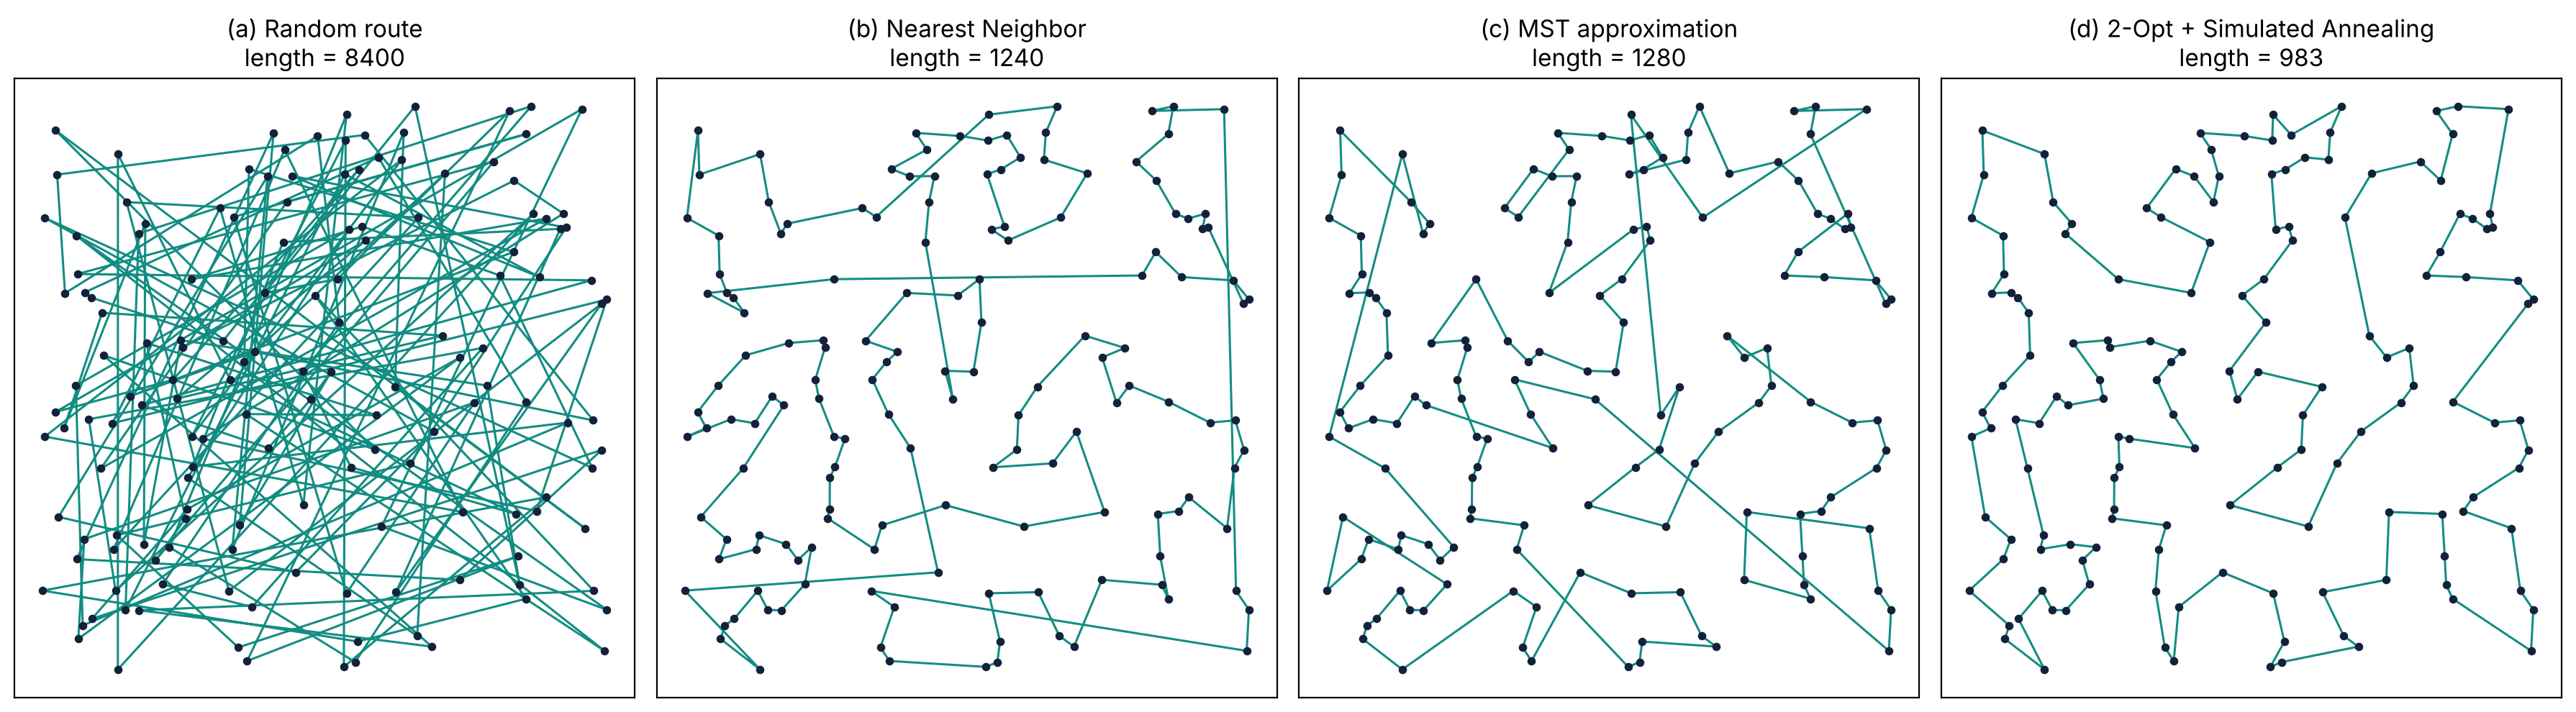

In [7]:
xs = [p[0] for p in points]
ys = [p[1] for p in points]


def draw(ax, route, title):
    ax.plot([xs[c] for c in route], [ys[c] for c in route], color="#138D82", linewidth=1.1)
    ax.scatter(xs, ys, s=10, color="#13213A", zorder=3)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")


fig, axes = plt.subplots(1, 4, figsize=(18, 4.9))
draw(axes[0], random_route, f"(a) Random route\nlength = {route_cost(random_route, D_big):.0f}")
draw(axes[1], nn_route, f"(b) Nearest Neighbor\nlength = {nn_cost:.0f}")
draw(axes[2], mst_route, f"(c) MST approximation\nlength = {mst_cost:.0f}")
draw(axes[3], sa_route, f"(d) 2-Opt + Simulated Annealing\nlength = {sa_cost:.0f}")
plt.tight_layout()
plt.savefig("stage5_exp2_routes.png", dpi=160, bbox_inches="tight")
plt.show()

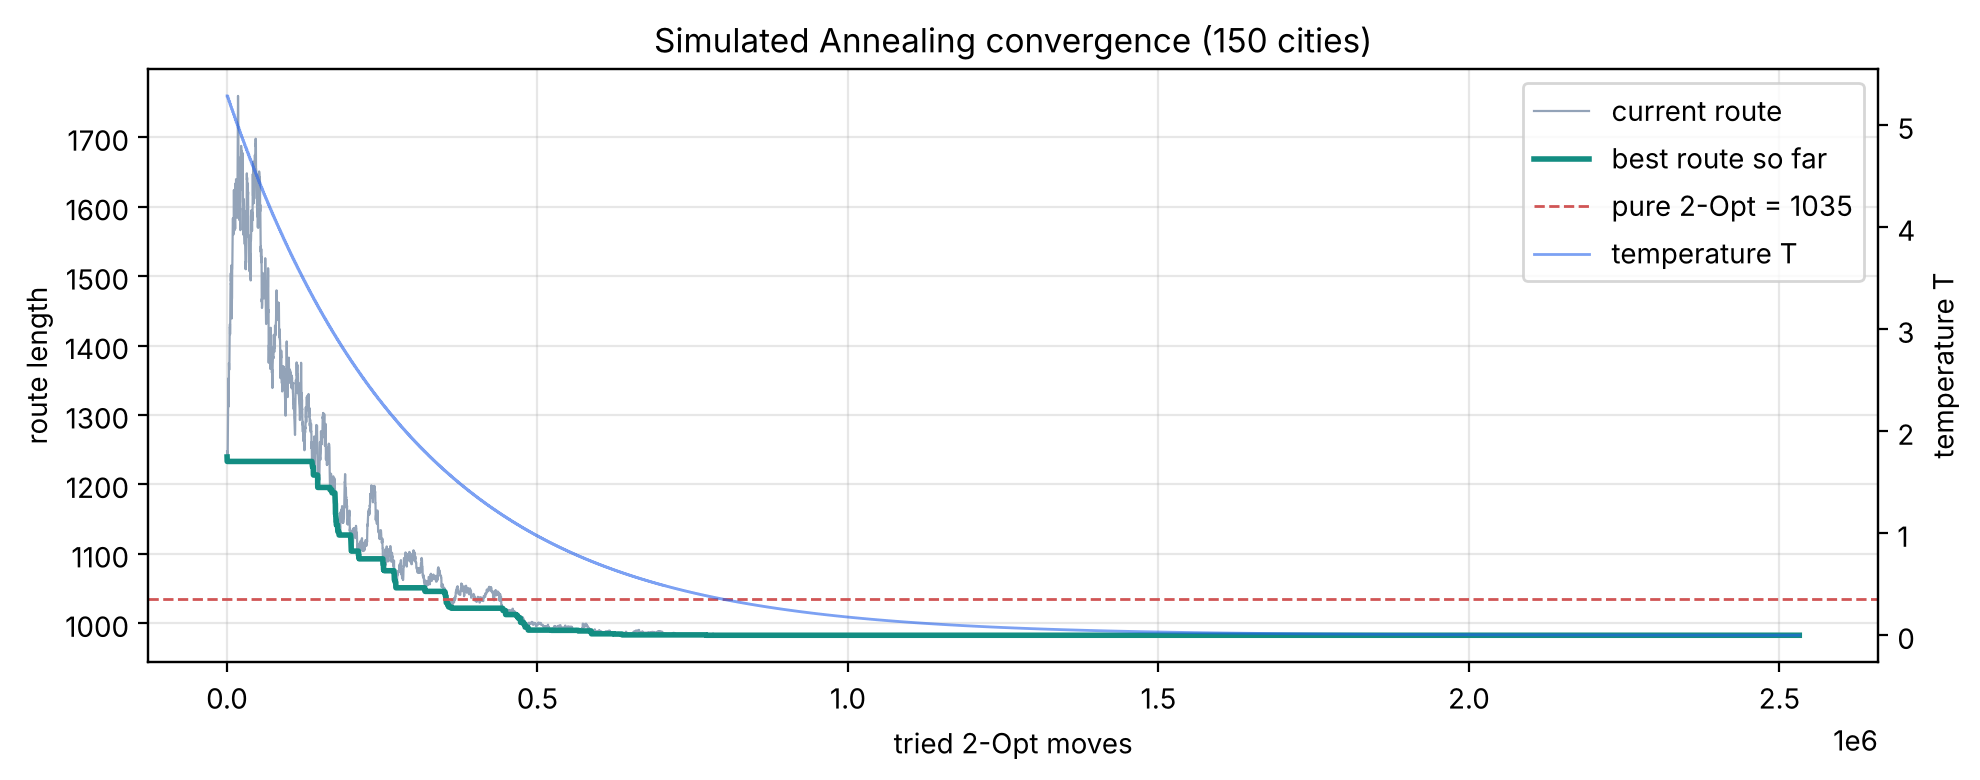

In [8]:
steps = [s for s, _, _, _ in sa_log]
current = [c for _, c, _, _ in sa_log]
best = [b for _, _, b, _ in sa_log]
temperature = [T for _, _, _, T in sa_log]

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(steps, current, color="#93A3B8", linewidth=0.8, label="current route")
ax1.plot(steps, best, color="#138D82", linewidth=2, label="best route so far")
ax1.axhline(opt2_cost, color="#D05555", ls="--", lw=1, label=f"pure 2-Opt = {opt2_cost:.0f}")
ax1.set_xlabel("tried 2-Opt moves")
ax1.set_ylabel("route length")
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(steps, temperature, color="#2563EB", linewidth=1, alpha=0.6, label="temperature T")
ax2.set_ylabel("temperature T")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")
ax1.set_title("Simulated Annealing convergence (150 cities)")
plt.tight_layout()
plt.savefig("stage5_sa_convergence.png", dpi=160, bbox_inches="tight")
plt.show()

At the start the temperature is high, so the current route often gets **worse** (the grey line goes up). This is how Simulated Annealing leaves local minima. When the temperature drops, the route settles **below** the result of pure 2-Opt (red line).

## Q5 - How Many Cities in Under 1 Second?

We measure the runtime of each algorithm for growing n and report the largest tested n that finishes in under 1 second (Python, one random map per size).

*Note: Simulated Annealing has a fixed cooling schedule, so its runtime is set by the number of moves we allow, not by n alone. It can be stopped earlier, with a slightly worse route.*

In [9]:
sizes = {
    "V1 Brute Force": [6, 7, 8, 9, 10, 11],
    "V2 Nearest Neighbor": [100, 200, 400, 800, 1600, 3200],
    "V3 Held-Karp": [10, 12, 14, 15, 16, 17],
    "V4 MST Approx.": [100, 200, 400, 800, 1600, 3200],
    "V5a Greedy + 2-Opt": [50, 100, 200, 400, 800],
    "V5b 2-Opt + SA": [10, 25, 50, 100],
}
functions = {"V1 Brute Force": brute_force, "V3 Held-Karp": held_karp, **ALGORITHMS}

max_n = {}
for name, ns in sizes.items():
    results = []
    for n in ns:
        D_test = distance_matrix(random_cities(n, 42))
        t = time.perf_counter()
        functions[name](D_test)
        results.append((n, time.perf_counter() - t))
    under = [n for n, s in results if s < 1]
    max_n[name] = max(under) if under else None
    print(f"{name:22}", "  ".join(f"n={n}: {s:.3f}s" for n, s in results))

print("\nLargest tested n under 1 second:")
for name, n in max_n.items():
    print(f"  {name:22} {n}")

V1 Brute Force         n=6: 0.000s  n=7: 0.000s  n=8: 0.002s  n=9: 0.017s  n=10: 0.168s  n=11: 1.730s


V2 Nearest Neighbor    n=100: 0.000s  n=200: 0.001s  n=400: 0.005s  n=800: 0.018s  n=1600: 0.066s  n=3200: 0.259s


V3 Held-Karp           n=10: 0.004s  n=12: 0.035s  n=14: 0.226s  n=15: 0.375s  n=16: 0.926s  n=17: 2.210s


V4 MST Approx.         n=100: 0.001s  n=200: 0.004s  n=400: 0.013s  n=800: 0.051s  n=1600: 0.203s  n=3200: 0.798s


V5a Greedy + 2-Opt     n=50: 0.001s  n=100: 0.004s  n=200: 0.019s  n=400: 0.115s  n=800: 0.660s


V5b 2-Opt + SA         n=10: 0.307s  n=25: 0.858s  n=50: 1.444s  n=100: 2.983s

Largest tested n under 1 second:
  V1 Brute Force         10
  V2 Nearest Neighbor    3200
  V3 Held-Karp           16
  V4 MST Approx.         3200
  V5a Greedy + 2-Opt     800
  V5b 2-Opt + SA         25


## Q5 - Comparison of All Five Stages

| Stage | Worst-case time | Extra space | Guarantee | Max n in < 1 s (Python, measured) |
|---|---|---|---|---|
| V1 Brute Force | Θ(n!) | Θ(n) | Exact OPT | ≈ 10 |
| V2 Nearest Neighbor | Θ(n²) | Θ(n) | None | ≈ 3 200 |
| V3 Held-Karp | Θ(n² · 2ⁿ) | Θ(n · 2ⁿ) | Exact OPT | ≈ 16 |
| V4 MST Approx. | O(n²) | Θ(n) | ≤ 2 · OPT (triangle inequality) | ≈ 3 200 |
| V5 2-Opt + SA | O(n²) per 2-Opt pass; O(K · n) for K SA moves | Θ(n) | None (local minimum), near-optimal in practice | ≈ 800 (2-Opt); ≈ 25 for SA with our cooling schedule |

The n × n distance matrix (Θ(n²) memory) is the input of every stage and is not counted as extra space. Exact measured numbers are printed in the cell above.

## Conclusion

- **Exact methods** (Brute Force, Held-Karp) always agree on OPT, but stop at about 10 and 16 cities within one second.
- **Nearest Neighbor** and the **MST approximation** scale to thousands of cities, but were 12 % and 22 % above OPT on average at n = 16. Only MST has a guarantee (≤ 2 · OPT on metric maps).
- **2-Opt** brings these routes back to about 1 % above OPT, and **Simulated Annealing** found the optimum on all 20 maps at n = 16.
- On 150 cities the route length drops from 1240 (Greedy) to 983 (2-Opt + SA), and all crossing edges disappear.